# ⚽ Premier League — Prédire le poste d'un joueur à partir de ses statistiques

**TP3 Big Data — Partie 1 (Machine Learning classique, sans big data)**

Exemple Kaggle de départ : [English Premier League Players Statistics](https://www.kaggle.com/code/desalegngeb/english-premier-league-players-statistics/notebook) (EDA uniquement).
Ce notebook reprend ce travail et le prolonge sur **tout le workflow** :

| # | Étape | Contenu |
|---|---|---|
| 1 | **Data** | chargement du dataset (571 joueurs, 59 colonnes) |
| 2 | **EDA** | répartition des postes, âges, stats clés, corrélations |
| 3 | **Prétraitement** | types, valeurs manquantes (et le piège qu'elles cachent), filtrage |
| 4 | **Transformation** | stats cumulées → stats **par match**, standardisation |
| 5 | **Machine Learning** | classification du poste (3 modèles) + clustering des profils |
| 6 | **Évaluation** | validation croisée, F1, matrice de confusion, importance des variables |
| 7 | **Déploiement** | sauvegarde du modèle + app **Streamlit** (`app/streamlit_app.py`) |

**Question posée :** *peut-on deviner si un joueur est défenseur, milieu ou attaquant uniquement à partir de ses statistiques ?*

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import features as F

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

## 1. Data

Dataset Kaggle : [`rishikeshkanabar/premier-league-player-statistics-updated-daily`](https://www.kaggle.com/datasets/rishikeshkanabar/premier-league-player-statistics-updated-daily) — snapshot du 24/09/2020, stats **cumulées sur la carrière en Premier League** de chaque joueur de l'effectif 2020-21.

In [2]:
raw = F.load_raw()
print(raw.shape)
raw.head()

(571, 59)


,Name,Jersey Number,Club,Position,Nationality,Age,Appearances,Wins,Losses,Goals,Goals per match,Headed goals,Goals with right foot,Goals with left foot,Penalties scored,Freekicks scored,Shots,Shots on target,Shooting accuracy %,Hit woodwork,Big chances missed,Clean sheets,Goals conceded,Tackles,Tackle success %,Last man tackles,Blocked shots,Interceptions,Clearances,Headed Clearance,Clearances off line,Recoveries,Duels won,Duels lost,Successful 50/50s,Aerial battles won,Aerial battles lost,Own goals,Errors leading to goal,Assists,Passes,Passes per match,Big chances created,Crosses,Cross accuracy %,Through balls,Accurate long balls,Saves,Penalties saved,Punches,High Claims,Catches,Sweeper clearances,Throw outs,Goal Kicks,Yellow cards,Red cards,Fouls,Offsides
0,Bernd Leno,1.0,Arsenal,Goalkeeper,Germany,28.0,64,28,16,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,82.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,7.0,0,1783,27.86,NaN,NaN,NaN,NaN,234.0,222.0,1.0,34.0,26.0,17.0,28.0,375.0,489.0,2,0,0,NaN
1,Matt Macey,33.0,Arsenal,Goalkeeper,England,26.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0,0,0.00,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NaN
2,Rúnar Alex Rúnarsson,13.0,Arsenal,Goalkeeper,Iceland,25.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0,0,0.00,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NaN
3,Héctor Bellerín,2.0,Arsenal,Defender,Spain,25.0,160,90,37,7,NaN,0.0,4.0,3.0,NaN,NaN,NaN,NaN,NaN,3.0,NaN,53.0,166.0,214.0,78%,1.0,32.0,208.0,304.0,143.0,3.0,732.0,611.0,709.0,196.0,161.0,215.0,1.0,1.0,18,7125,44.53,28.0,389.0,16%,31.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23,0,125,8.0
4,Kieran Tierney,3.0,Arsenal,Defender,Scotland,23.0,16,7,5,1,NaN,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,2.0,16.0,21.0,81%,0.0,1.0,12.0,32.0,12.0,0.0,63.0,55.0,38.0,12.0,10.0,16.0,0.0,0.0,1,519,32.44,1.0,45.0,18%,0.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0,9,0.0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 571 entries, 0 to 570
Data columns (total 59 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Name                    571 non-null    str    
 1   Jersey Number           563 non-null    float64
 2   Club                    571 non-null    str    
 3   Position                571 non-null    str    
 4   Nationality             570 non-null    str    
 5   Age                     570 non-null    float64
 6   Appearances             571 non-null    int64  
 7   Wins                    571 non-null    int64  
 8   Losses                  571 non-null    int64  
 9   Goals                   571 non-null    int64  
 10  Goals per match         309 non-null    float64
 11  Headed goals            502 non-null    float64
 12  Goals with right foot   502 non-null    float64
 13  Goals with left foot    502 non-null    float64
 14  Penalties scored        309 non-null    float64
 15  

## 2. EDA — Analyse exploratoire

L'EDA détaillée (nationalités, clubs, meilleurs buteurs…) est faite dans le notebook Kaggle d'origine.
Ici on se concentre sur ce qui sert la question : **les postes se distinguent-ils par leurs stats ?**

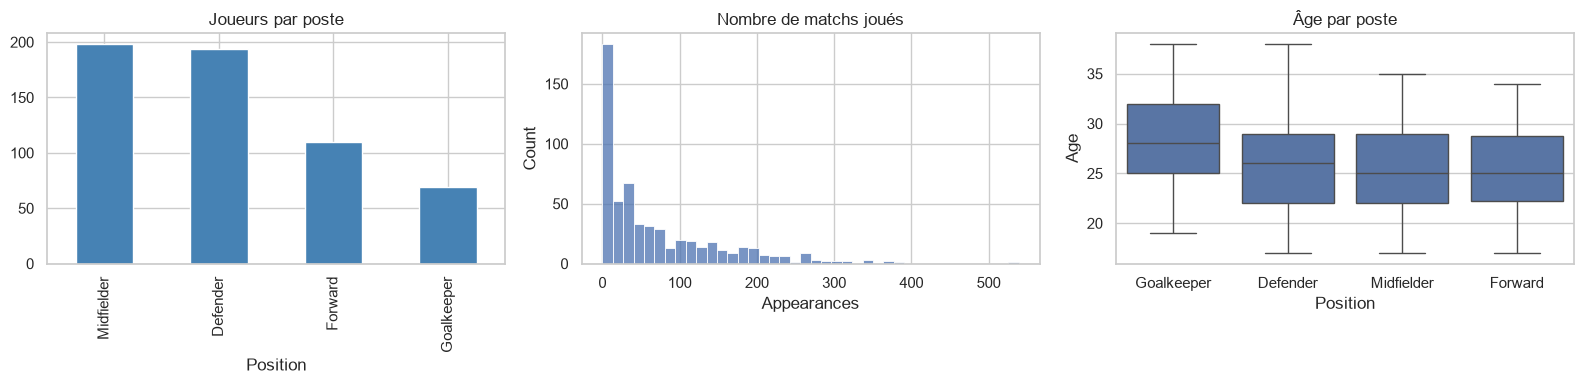

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
raw["Position"].value_counts().plot.bar(ax=axes[0], color="steelblue", title="Joueurs par poste")
sns.histplot(raw["Appearances"], bins=40, ax=axes[1]).set_title("Nombre de matchs joués")
sns.boxplot(data=raw, x="Position", y="Age", ax=axes[2]).set_title("Âge par poste")
plt.tight_layout(); plt.show()

- Classes assez équilibrées entre défenseurs (194) et milieux (198), moins d'attaquants (110).
- Le nombre de matchs est **très asymétrique** : beaucoup de joueurs n'ont presque pas joué → leurs stats sont du bruit (à filtrer).

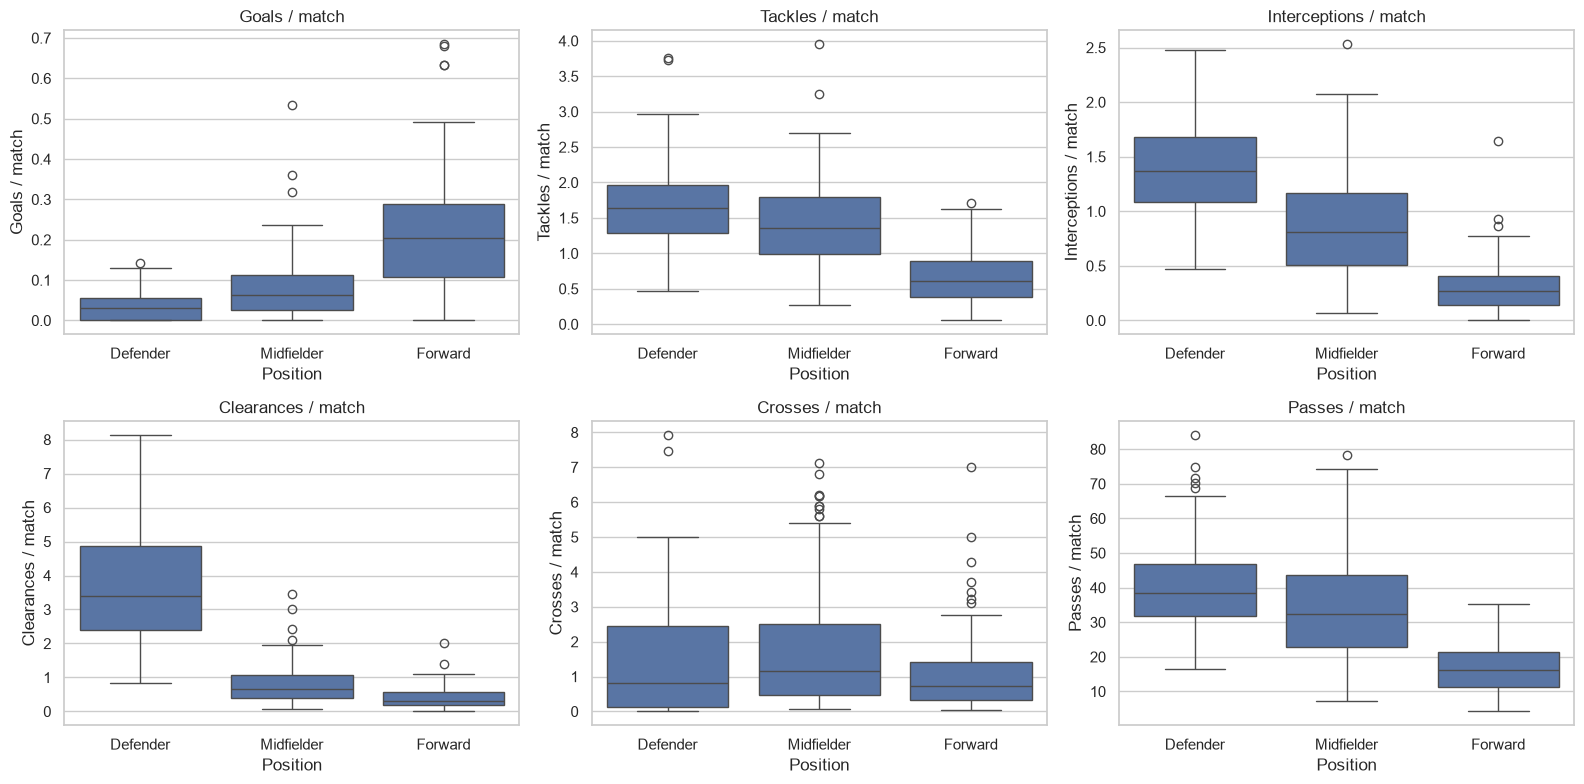

In [5]:
tmp = raw[raw["Appearances"] >= 10].copy()
for c in ["Goals", "Tackles", "Interceptions", "Clearances", "Crosses", "Passes"]:
    tmp[c + " / match"] = tmp[c] / tmp["Appearances"]
cols = ["Goals / match", "Tackles / match", "Interceptions / match", "Clearances / match", "Crosses / match", "Passes / match"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, cols):
    sns.boxplot(data=tmp[tmp.Position != "Goalkeeper"], x="Position", y=c, ax=ax, order=F.POSITIONS)
    ax.set_title(c)
plt.tight_layout(); plt.show()

Les postes ont des **signatures statistiques nettes** : buts pour les attaquants, dégagements pour les défenseurs, passes pour les milieux.
Le milieu est la classe « intermédiaire » : on s'attend à ce que le modèle la confonde le plus.

## 3. Prétraitement

### 3.1 Le piège des valeurs manquantes ⚠️

Regardons le taux de valeurs manquantes **par poste** :

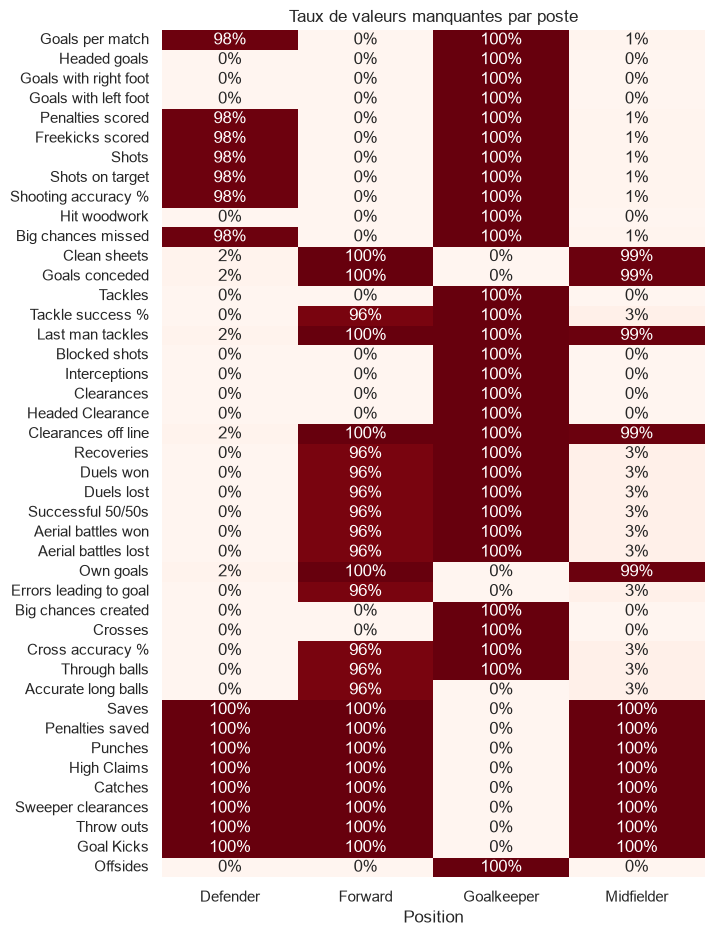

In [6]:
na_by_pos = raw.drop(columns=["Name", "Club", "Nationality"]).isna().groupby(raw["Position"]).mean().T
na_by_pos = na_by_pos[(na_by_pos > 0.05).any(axis=1)]
plt.figure(figsize=(7, 11))
sns.heatmap(na_by_pos, cmap="Reds", annot=True, fmt=".0%", cbar=False)
plt.title("Taux de valeurs manquantes par poste"); plt.show()

Le site de la Premier League **n'affiche pas les mêmes stats selon le poste** : `Shots` manque pour 98 % des défenseurs, `Recoveries` ou `Duels won` pour 96 % des attaquants, etc.

➡️ Si on remplaçait ces vides par 0, le modèle apprendrait *« pas de tirs renseignés = défenseur »* : il tricherait (**fuite de données**) avec un score quasi parfait mais sans intérêt.

**Décision :** on ne garde que les **17 statistiques renseignées pour tous les postes de champ** (liste `F.COUNT_STATS`).

In [7]:
print(len(F.COUNT_STATS), "stats retenues :", F.COUNT_STATS)

17 stats retenues : ['Goals', 'Headed goals', 'Goals with right foot', 'Goals with left foot', 'Hit woodwork', 'Assists', 'Big chances created', 'Passes', 'Crosses', 'Tackles', 'Blocked shots', 'Interceptions', 'Clearances', 'Headed Clearance', 'Fouls', 'Offsides', 'Yellow cards']


### 3.2 Nettoyage

- conversion des colonnes `%` (texte `"81%"`) en nombres ;
- suppression des lignes sans âge / nationalité ;
- **exclusion des gardiens** : leurs stats (arrêts, clean sheets) les identifient à coup sûr, la tâche serait triviale ;
- **filtrage des joueurs avec moins de 10 matchs** (stats trop bruitées) ;
- vides restants dans les stats retenues → 0 (moins de 1 % des cas, correspond à « aucun événement »).

In [8]:
df = F.clean(raw)
print(f"{len(raw)} joueurs -> {len(df)} après nettoyage")
df["Position"].value_counts()

571 joueurs -> 366 après nettoyage


Position
Midfielder    146
Defender      129
Forward        91
Name: count, dtype: int64

## 4. Transformation

Les stats sont **cumulées sur la carrière** : un joueur à 300 matchs a mécaniquement plus de tacles qu'un joueur à 20 matchs.
On les ramène **par match** pour comparer des profils, pas des carrières.

In [9]:
df = F.add_per_match(df)
X = df[F.FEATURES]
y = df["Position"]
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Goals / match,366.0,0.098,0.114,0.000,0.024,0.060,0.132,0.684
Headed goals / match,366.0,0.016,0.027,0.000,0.000,0.000,0.023,0.139
Goals with right foot / match,366.0,0.053,0.077,0.000,0.000,0.024,0.071,0.533
Goals with left foot / match,366.0,0.028,0.051,0.000,0.000,0.008,0.035,0.512
Hit woodwork / match,366.0,0.025,0.029,0.000,0.000,0.017,0.038,0.200
Assists / match,366.0,0.075,0.066,0.000,0.028,0.062,0.104,0.467
Big chances created / match,366.0,0.107,0.090,0.000,0.041,0.083,0.158,0.622
Passes / match,366.0,32.160,15.524,4.226,20.640,31.214,41.977,84.017
Crosses / match,366.0,1.512,1.596,0.000,0.299,0.907,2.340,7.917
Tackles / match,366.0,1.327,0.665,0.053,0.810,1.290,1.731,3.951


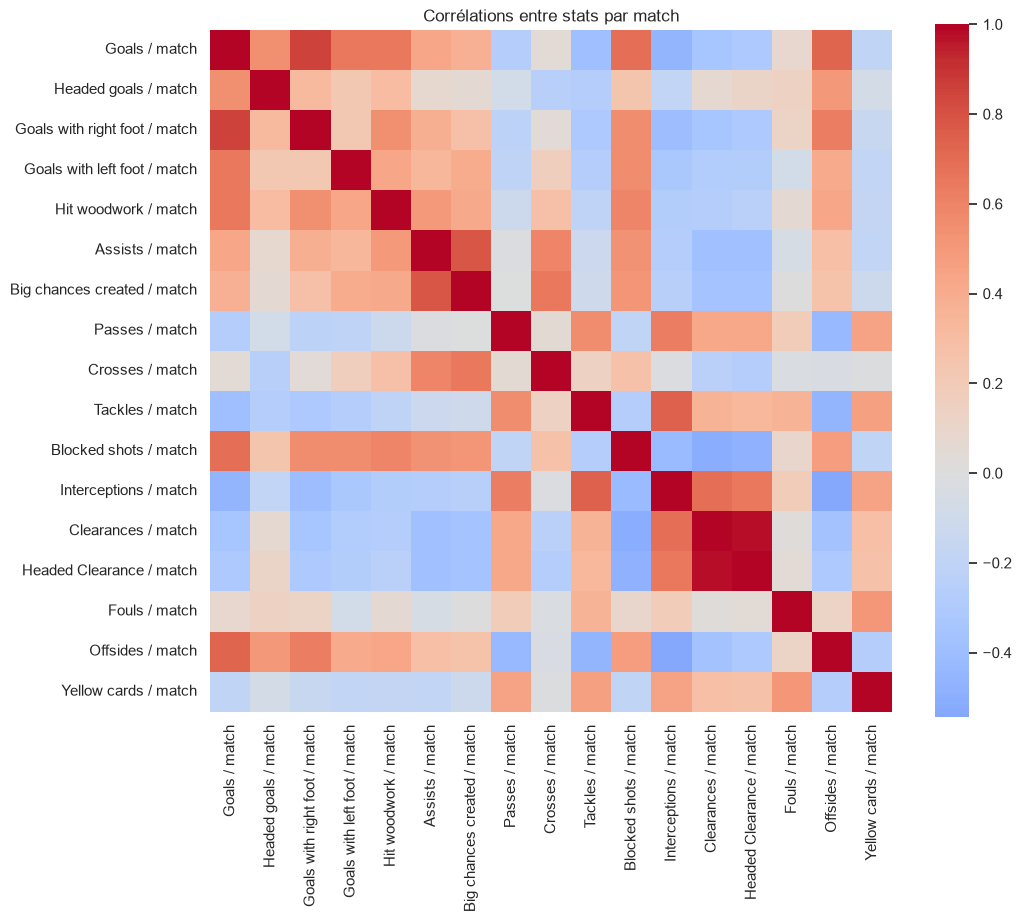

In [10]:
plt.figure(figsize=(11, 9))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, square=True)
plt.title("Corrélations entre stats par match"); plt.show()

Les échelles sont très différentes (≈ 30 passes/match contre ≈ 0,05 but de la tête/match) → **standardisation** (`StandardScaler`) intégrée dans un `Pipeline` scikit-learn, pour qu'elle soit apprise uniquement sur les données d'entraînement (pas de fuite) et réappliquée automatiquement au moment de la prédiction.

## 5. Machine Learning

### 5.1 Classification du poste

Découpage **train 80 % / test 20 %** stratifié. Le test n'est utilisé qu'à la toute fin.
Trois modèles comparés par **validation croisée stratifiée à 5 plis** sur le train (petit dataset → une seule découpe serait trop aléatoire).

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

models = {
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({"modèle": name,
                 "accuracy": s["test_accuracy"].mean(), "accuracy ±": s["test_accuracy"].std(),
                 "F1 macro": s["test_f1_macro"].mean(), "F1 macro ±": s["test_f1_macro"].std()})
cv_results = pd.DataFrame(rows).set_index("modèle").round(3)
cv_results

,accuracy,accuracy ±,F1 macro,F1 macro ±
modèle,,,,
Régression logistique,0.867,0.038,0.866,0.036
Random Forest,0.870,0.030,0.869,0.026
Gradient Boosting,0.846,0.022,0.845,0.018


### 5.2 Optimisation des hyperparamètres

Recherche sur grille (`GridSearchCV`, même validation croisée) pour la régression logistique (force de régularisation `C`) et le Random Forest.

In [12]:
grids = {
    "Régression logistique": (LogisticRegression(max_iter=2000), {"model__C": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
                      {"model__n_estimators": [200, 500], "model__max_depth": [None, 6, 10],
                       "model__min_samples_leaf": [1, 3]}),
}
searches = {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("model", model)]),
                      grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name:22s} F1 CV = {gs.best_score_:.3f}  {gs.best_params_}")

best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = searches[best_name].best_estimator_
print("\nModèle retenu :", best_name)

Régression logistique  F1 CV = 0.870  {'model__C': 10}


Random Forest          F1 CV = 0.872  {'model__max_depth': 6, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}

Modèle retenu : Random Forest


## 6. Évaluation

### 6.1 Sur le jeu de test (jamais vu)

{'accuracy': 0.8513513513513513, 'f1_macro': 0.8516554162648666}
              precision    recall  f1-score   support

    Defender      0.920     0.885     0.902        26
     Forward      0.833     0.833     0.833        18
  Midfielder      0.806     0.833     0.820        30

    accuracy                          0.851        74
   macro avg      0.853     0.850     0.852        74
weighted avg      0.853     0.851     0.852        74



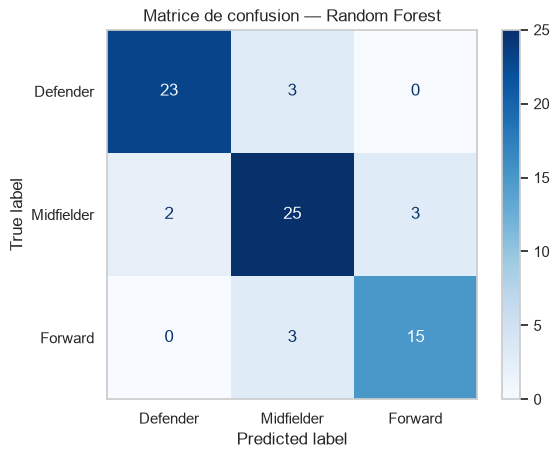

In [13]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

y_pred = best_model.predict(X_test)
test_metrics = {"accuracy": accuracy_score(y_test, y_pred), "f1_macro": f1_score(y_test, y_pred, average="macro")}
print(test_metrics)
print(classification_report(y_test, y_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=F.POSITIONS, cmap="Blues")
plt.title(f"Matrice de confusion — {best_name}"); plt.grid(False); plt.show()

Comme prévu, les erreurs se concentrent sur les **milieux**, poste intermédiaire (milieux défensifs ≈ défenseurs, milieux offensifs ≈ attaquants).
Un classifieur au hasard ferait ≈ 33 % : le modèle capte clairement l'information.

### 6.2 Quelles stats comptent ? (importance par permutation)

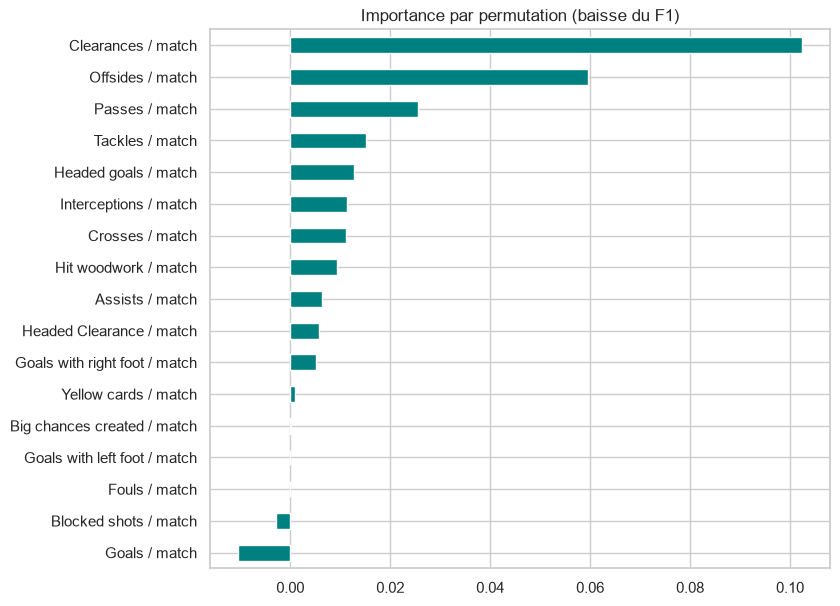

In [14]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(best_model, X_test, y_test, scoring="f1_macro",
                            n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(imp.importances_mean, index=F.FEATURES).sort_values()
imp.plot.barh(figsize=(8, 7), color="teal", title="Importance par permutation (baisse du F1)")
plt.show()

### 6.3 Les « erreurs » intéressantes

Sur tout le dataset (prédictions en validation croisée), quels joueurs ont un profil statistique différent de leur poste officiel ?

In [15]:
from sklearn.model_selection import cross_val_predict
df["Poste prédit"] = cross_val_predict(best_model, X, y, cv=cv)
errors = df[df["Poste prédit"] != df["Position"]][["Name", "Club", "Position", "Poste prédit", "Appearances"]]
print(f"{len(errors)} joueurs « mal classés » sur {len(df)}")
errors.sort_values("Appearances", ascending=False).head(15)

47 joueurs « mal classés » sur 366


,Name,Club,Position,Poste prédit,Appearances
69,Jack Cork,Burnley,Midfielder,Defender,264
23,Willian,Arsenal,Forward,Midfielder,236
288,Ryan Bertrand,Southampton,Defender,Midfielder,231
215,Fernandinho,Manchester-City,Midfielder,Defender,225
114,Wilfried Zaha,Crystal-Palace,Forward,Midfielder,217
240,Nemanja Matic,Manchester-United,Midfielder,Defender,208
220,Riyad Mahrez,Manchester-City,Forward,Midfielder,199
107,Cheikhou Kouyaté,Crystal-Palace,Midfielder,Defender,197
311,Eric Dier,Tottenham-Hotspur,Midfielder,Defender,176
322,Gareth Bale,Tottenham-Hotspur,Forward,Midfielder,146


Ces « erreurs » sont souvent explicables : latéraux très offensifs prédits milieux, milieux offensifs prédits attaquants… Le poste officiel est une étiquette grossière, le modèle voit le **style de jeu**.

### 6.4 (bonus) Clustering — découvrir des profils sans utiliser le poste

On oublie l'étiquette et on laisse **KMeans** regrouper les joueurs. Choix de `k` par le score de silhouette, visualisation en 2D par **ACP (PCA)**.

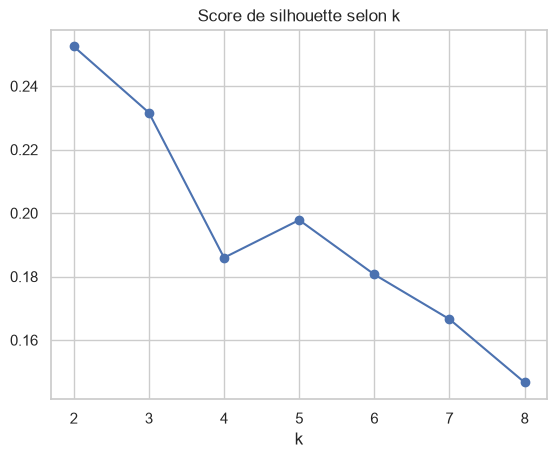

In [16]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

X_scaled = StandardScaler().fit_transform(X)
sil = {k: silhouette_score(X_scaled, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled))
       for k in range(2, 9)}
pd.Series(sil).plot(marker="o", title="Score de silhouette selon k"); plt.xlabel("k"); plt.show()

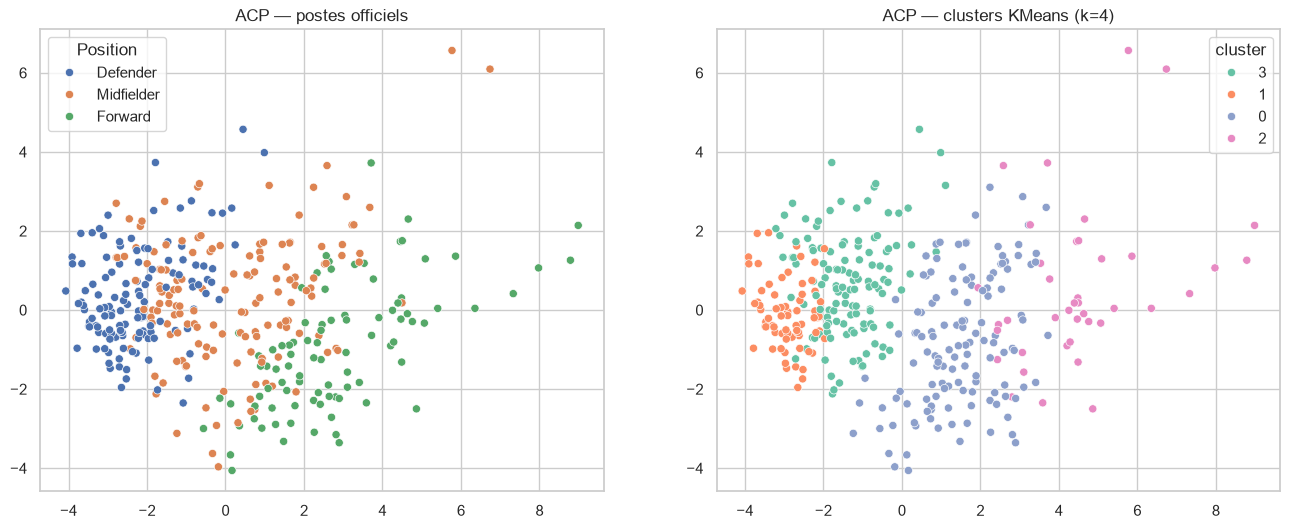

Position,Defender,Forward,Midfielder
cluster,,,
0,3,56,71
1,69,0,2
2,0,35,5
3,57,0,68


In [17]:
K = 4  # compromis lisibilité / silhouette : un groupe de plus que les 3 postes
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
df["cluster"] = km.labels_
coords = PCA(2, random_state=RANDOM_STATE).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["Position"], ax=axes[0], s=35).set_title("ACP — postes officiels")
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["cluster"].astype(str), palette="Set2", ax=axes[1], s=35).set_title(f"ACP — clusters KMeans (k={K})")
plt.show()
pd.crosstab(df["cluster"], df["Position"])

In [18]:
# Profil moyen de chaque cluster (z-scores) pour les nommer
profile = pd.DataFrame(km.cluster_centers_, columns=F.FEATURES).T.round(2)
profile.style.background_gradient(cmap="RdBu_r", axis=None)

,0,1,2,3
Goals / match,0.100000,-0.500000,2.220000,-0.530000
Headed goals / match,-0.260000,0.260000,1.740000,-0.440000
Goals with right foot / match,0.110000,-0.530000,1.870000,-0.410000
Goals with left foot / match,0.190000,-0.460000,1.210000,-0.320000
Hit woodwork / match,0.120000,-0.450000,1.570000,-0.370000
Assists / match,0.270000,-0.790000,1.010000,-0.160000
Big chances created / match,0.290000,-0.730000,0.820000,-0.150000
Passes / match,-0.740000,0.780000,-0.500000,0.490000
Crosses / match,0.250000,-0.730000,-0.100000,0.180000
Tackles / match,-0.680000,0.240000,-0.780000,0.820000


Les clusters retrouvent les grands postes mais font apparaître des **profils plus fins** (ex. défenseurs centraux « dégageurs » vs latéraux « centreurs », milieux relayeurs vs créateurs).
Lire le tableau ci-dessus : une valeur > 0 = au-dessus de la moyenne pour cette stat.

## 7. Déploiement

On réentraîne le meilleur modèle sur **toutes les données** puis on le sauvegarde (`joblib`) avec ses métadonnées.
L'app Streamlit `app/streamlit_app.py` le recharge et applique **les mêmes transformations** (`src/features.py`).

```bash
streamlit run app/streamlit_app.py
```

In [19]:
import joblib, sklearn

final_model = best_model.fit(X, y)
models_dir = ROOT / "models"
models_dir.mkdir(exist_ok=True)
joblib.dump(final_model, models_dir / "position_model.joblib")

metadata = {
    "model": best_name,
    "params": searches[best_name].best_params_,
    "features": F.FEATURES,
    "classes": list(final_model.classes_),
    "cv_f1_macro": round(searches[best_name].best_score_, 4),
    "test_accuracy": round(test_metrics["accuracy"], 4),
    "test_f1_macro": round(test_metrics["f1_macro"], 4),
    "n_train_rows": len(X),
    "sklearn_version": sklearn.__version__,
}
(models_dir / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
metadata

{'model': 'Random Forest',
 'params': {'model__max_depth': 6,
  'model__min_samples_leaf': 1,
  'model__n_estimators': 200},
 'features': ['Goals / match',
  'Headed goals / match',
  'Goals with right foot / match',
  'Goals with left foot / match',
  'Hit woodwork / match',
  'Assists / match',
  'Big chances created / match',
  'Passes / match',
  'Crosses / match',
  'Tackles / match',
  'Blocked shots / match',
  'Interceptions / match',
  'Clearances / match',
  'Headed Clearance / match',
  'Fouls / match',
  'Offsides / match',
  'Yellow cards / match'],
 'classes': ['Defender', 'Forward', 'Midfielder'],
 'cv_f1_macro': np.float64(0.8722),
 'test_accuracy': 0.8514,
 'test_f1_macro': 0.8517,
 'n_train_rows': 366,
 'sklearn_version': '1.9.1'}

## Conclusion

- Avec **17 stats par match**, on retrouve le poste d'un joueur de champ dans environ 85 % des cas (F1 ≈ 0,85 sur le test, 0,87 en validation croisée), contre 33 % au hasard.
- Le **prétraitement** a été décisif : sans repérer que les valeurs manquantes trahissaient le poste, on aurait obtenu un score artificiellement parfait.
- La difficulté principale est le **milieu de terrain**, poste hybride ; le clustering confirme qu'il recouvre plusieurs profils.
- **Pourquoi pas de big data ici ?** ~400 lignes × 17 colonnes tiennent en quelques Ko : pandas/scikit-learn sont parfaitement adaptés, Spark n'apporterait que de la complexité (comparer avec la partie 2).